# Assignment 1: Neural Networks for California Housing

This notebook guides you through a regression task (predicting house value) and a binary classification task (predicting whether house value is at least $200,000). Complete the written observations as you go.

**Important:** use validation data for model selection. Keep the test data untouched until the final evaluation.

## 1. Imports and reproducibility

Set seeds so repeated runs are more comparable. `DEVICE` uses a GPU if PyTorch can access one; otherwise, computation runs on the CPU.

In [3]:
from copy import deepcopy
from itertools import product
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.datasets import fetch_california_housing
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    mean_squared_error,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

# rng seed
SEED = 302          # 302 was used in assignment sheet, so we use it here as well
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# from housing dataset
FEATURE_NAMES = [
    "MedInc", "HouseAge", "AveRooms", "AveBedrms",
    "Population", "AveOccup", "Latitude", "Longitude",
]

# use gpu if compatible/available
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    print("GPU used:", torch.cuda.get_device_name(torch.cuda.current_device()))

Using device: cuda
GPU used: NVIDIA GeForce RTX 4080 SUPER


## 2. Load and inspect the data

The provided split reserves 25% of the data for final testing. Do not use that test split to choose a model or hyperparameters.

In [4]:
def load_data():
    """Fetch California housing data and make the assignment train/test split."""
    X, y = fetch_california_housing(return_X_y=True)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.25, random_state=SEED
    )
    return X_train, X_test, y_train, y_test


X_train, X_test, y_train, y_test = load_data()
print(f"Training features: {X_train.shape}; training targets: {y_train.shape}")
print(f"Test features: {X_test.shape}; test targets: {y_test.shape}")
pd.DataFrame(X_train, columns=FEATURE_NAMES).head()

Training features: (15480, 8); training targets: (15480,)
Test features: (5160, 8); test targets: (5160,)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,3.3409,32.0,3.254902,1.009804,177.0,1.735294,33.90,-118.37
1,4.0000,35.0,4.938095,0.985714,552.0,2.628571,37.71,-122.12
2,4.1997,17.0,5.732759,1.060345,2866.0,3.088362,38.66,-121.76
3,5.6163,27.0,6.515670,1.005698,1140.0,3.247863,33.83,-117.87
4,1.6559,48.0,5.161663,1.000000,1363.0,3.147806,33.99,-118.31


## 3. Explore the training features

Use training data only for this exploration. Look at the distributions and summary statistics before deciding how to preprocess the inputs.

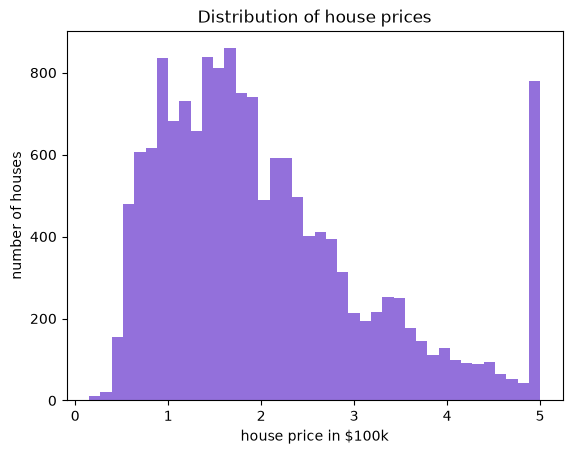

,medHouseVal
count,15480.000000
mean,2.068206
std,1.156928
min,0.149990
25%,1.189000
50%,1.798000
75%,2.647000
max,5.000010


In [5]:
plt.hist(y_train, bins=40, color="mediumpurple")
plt.xlabel("house price in $100k")
plt.ylabel("number of houses")
plt.title("Distribution of house prices")
plt.show()

frame = pd.DataFrame({"medHouseVal": y_train})
frame.describe()

**Your observations:** Which features appear skewed? Do feature ranges differ substantially? Do you notice possible outliers or other notable distributions? Use the plots and summary statistics to support your comments.

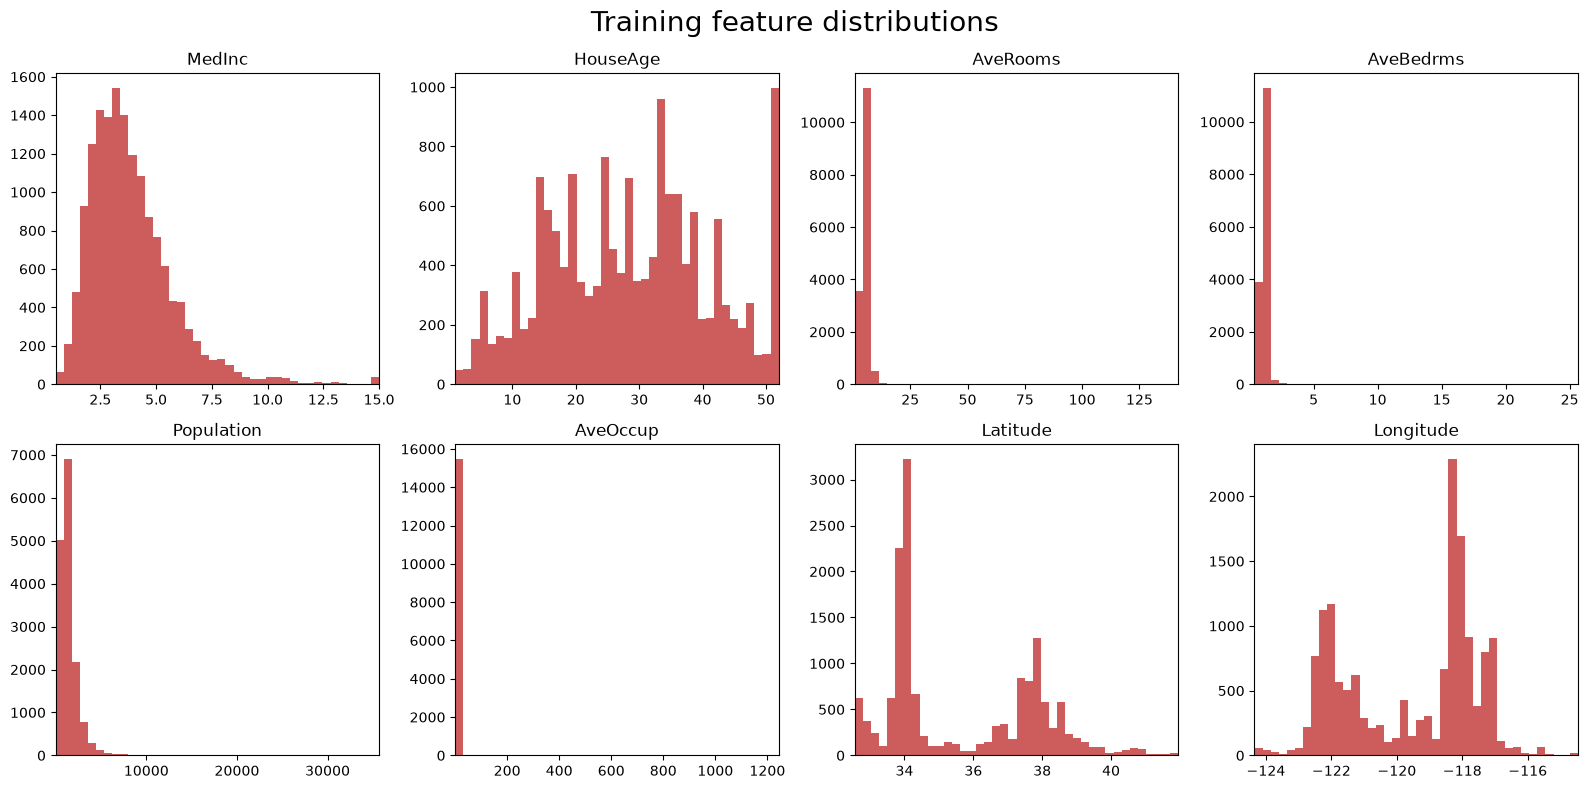

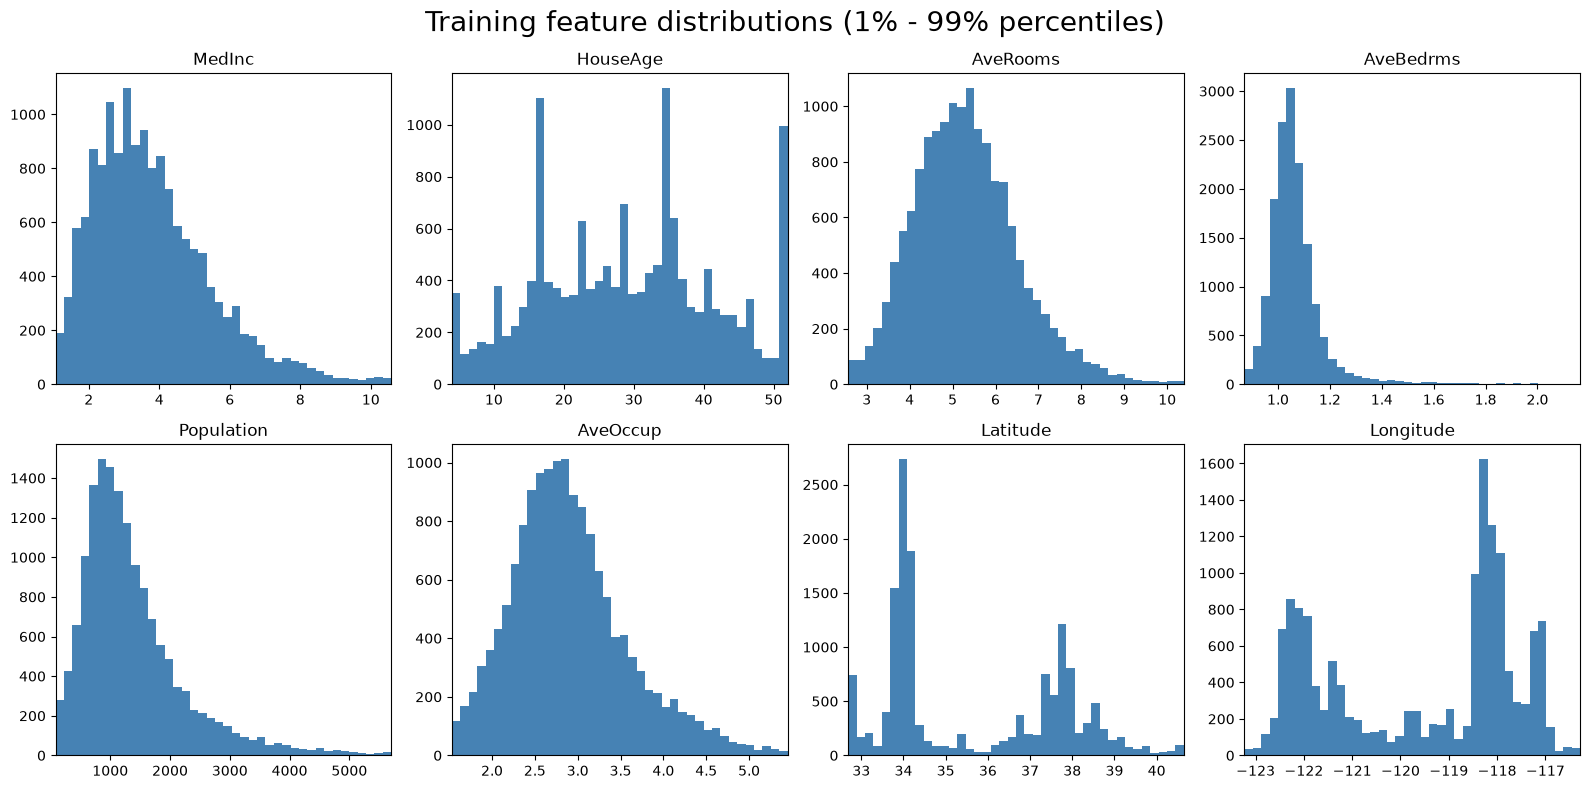

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,15480.000000,15480.000000,15480.000000,15480.000000,15480.000000,15480.000000,15480.000000,15480.000000
mean,3.867932,28.634044,5.431607,1.095960,1421.528811,3.112156,35.634422,-119.569263
std,1.899344,12.642321,2.388734,0.427406,1124.197972,11.959223,2.138867,2.004747
min,0.499900,1.000000,0.846154,0.375000,3.000000,0.692308,32.560000,-124.350000
25%,2.565800,18.000000,4.443769,1.006118,787.000000,2.431797,33.930000,-121.790000
50%,3.528800,29.000000,5.230702,1.048833,1163.000000,2.823972,34.250000,-118.490000
75%,4.744150,37.000000,6.060497,1.099431,1719.250000,3.282093,37.720000,-118.000000
max,15.000100,52.000000,141.909091,25.636364,35682.000000,1243.333333,41.950000,-114.470000


In [6]:
def analyse_features(X_set, color="steelblue", lower_pc=0, upper_pc=1):
    frame = pd.DataFrame(X_set, columns=FEATURE_NAMES)
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))

    for ax, feature in zip(axes.flat, frame.columns):
        values = frame[feature]

        #ax.hist(values, bins=40)
        lower, upper = values.quantile([lower_pc, upper_pc])
        ax.hist(values, bins=40, range=(lower, upper),color=color)
        ax.set_xlim(lower, upper)

        ax.set_title(feature)

    if lower_pc != 0 and upper_pc != 1:
        plt.suptitle(f"Training feature distributions ({lower_pc:.0%} - {upper_pc:.0%} percentiles)",fontsize=20)
    else:
        plt.suptitle("Training feature distributions",fontsize=20)
    plt.tight_layout()
    plt.show()
    return frame.describe()

analyse_features(X_train,color="indianred")
analyse_features(X_train,lower_pc=0.01,upper_pc=0.99)

## 4. Make a regression training/validation split

The validation data is used to compare candidate models. Fit the scaler on the subtraining data only, then use that fitted scaler to transform validation inputs. This avoids leaking information from validation into preprocessing.

In [7]:
X_subtrain, X_vld, y_subtrain, y_vld = train_test_split(
    X_train, y_train, test_size=0.2, random_state=SEED
)

scaler = StandardScaler()
X_subtrain_scaled = scaler.fit_transform(X_subtrain)
X_vld_scaled = scaler.transform(X_vld)
print(f"Subtraining: {X_subtrain_scaled.shape}; validation: {X_vld_scaled.shape}")

Subtraining: (12384, 8); validation: (3096, 8)


## 5. PyTorch data and model helpers

A `DataLoader` supplies mini-batches. The network has fully connected (`Linear`) layers and ReLU activations. For regression, its output is one unrestricted value because the target is continuous and the model should not constrain predictions to a class range. Mean squared error (MSE) is suitable for measuring the squared difference between prediction and target. In training, `loss.backward()` computes gradients and `optimizer.step()` updates the parameters.

In your report, explain your choices for the hidden layers/units, scalar output layer, MSE loss, SGD, and mini-batch size. Relate the choices to the regression target and the observed training/validation behavior.

In [8]:
def make_loader(X, y, batch_size, shuffle):
    x_tensor = torch.as_tensor(X, dtype=torch.float32)
    y_tensor = torch.as_tensor(y, dtype=torch.float32).reshape(-1, 1)
    dataset = TensorDataset(x_tensor, y_tensor)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)


class FeedForwardNetwork(nn.Module):
    def __init__(self, hidden_units, output_units=1):
        super().__init__()
        layers = []
        input_units = len(FEATURE_NAMES)                                    # e.g. 8 features = 8 input neurons
        for units in hidden_units:                                          # tupels e.g. (8,8,8) = 3 hidden layers with 8 hidden units
            layers.extend([nn.Linear(input_units, units),nn.ReLU()])        # layer + ReLU nonLin
            input_units = units
        layers.append(nn.Linear(input_units, output_units))                 # output layer = 1 outpur neuron (1 target val regression)
        self.network = nn.Sequential(*layers)                               # unpack layer list and feed the network (sequential)

    def forward(self, x):
        return self.network(x)


def train_model(
    model,
    train_loader,
    val_loader,
    *,
    epochs,
    learning_rate,
    loss_fn,
    progress_label="Training",
):
    optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
    history = {"train_loss": []}
    if val_loader is not None:
        history["val_loss"] = []
    print(f"{progress_label} started ({epochs} epochs).", flush=True)

    for epoch in range(epochs):
        model.train()
        train_total = 0.0
        train_count = 0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            predictions = model(xb)
            loss = loss_fn(predictions, yb)
            loss.backward()
            optimizer.step()
            train_total += loss.item() * len(xb)
            train_count += len(xb)
        history["train_loss"].append(train_total / train_count)

        if val_loader is not None:
            model.eval()
            val_total = 0.0
            val_count = 0
            with torch.no_grad():
                for xb, yb in val_loader:
                    xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                    loss = loss_fn(model(xb), yb)
                    val_total += loss.item() * len(xb)
                    val_count += len(xb)
            history["val_loss"].append(val_total / val_count)

        if (epoch + 1) % 10 == 0 or epoch == 0 or epoch + 1 == epochs:
            message = (
                f"{progress_label} | epoch {epoch + 1}/{epochs} | "
                f"train loss: {history['train_loss'][-1]:.4f}"
            )
            if val_loader is not None:
                message += f" | validation loss: {history['val_loss'][-1]:.4f}"
            print(message, flush=True)

    return model, history


def predict(model, X):
    model.eval()
    x_tensor = torch.as_tensor(X, dtype=torch.float32, device=DEVICE)
    with torch.no_grad():
        return model(x_tensor).cpu().numpy()

## 6. Select a regression model

This compares 12 architecture/learning-rate combinations. It can take a few minutes on CPU. Validation MSE is the selection criterion; do not use test MSE here.

In [9]:
configurations = [
    {
        "hidden_units": hidden_units,
        "learning_rate": learning_rate,
        "epochs": epochs,
        "batch_size": batch_size,
    }
    for hidden_units, learning_rate, epochs, batch_size in product(
        [(32,), (64,), (128,), (64, 32), (128, 64), (64, 64, 64)],
        [0.01, 0.001],
        [100],
        [64],
    )
]

results = []
best_config = None
best_val_loss = float("inf")
best_history = None

for config_index, config in enumerate(configurations, start=1):
    progress_label = f"Configuration {config_index}/{len(configurations)}"
    print(f"Starting {progress_label}: {config}", flush=True)
    train_loader = make_loader(
        X_subtrain_scaled, y_subtrain, config["batch_size"], shuffle=True
    )
    val_loader = make_loader(
        X_vld_scaled, y_vld, config["batch_size"], shuffle=False
    )
    model = FeedForwardNetwork(config["hidden_units"]).to(DEVICE)
    model, history = train_model(
        model,
        train_loader,
        val_loader,
        epochs=config["epochs"],
        learning_rate=config["learning_rate"],
        loss_fn=nn.MSELoss(),
        progress_label=progress_label,
    )
    train_loss = history["train_loss"][-1]
    val_loss = history["val_loss"][-1]
    print(
        f"Finished {progress_label} | train loss: {train_loss:.4f} | "
        f"validation loss: {val_loss:.4f}",
        flush=True,
    )
    results.append({**config, "train_loss": train_loss, "val_loss": val_loss})
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_config = config
        best_history = deepcopy(history)

results_frame = pd.DataFrame(results).sort_values("val_loss")
display(results_frame)
print("Selected configuration:", best_config)

Starting Configuration 1/12: {'hidden_units': (32,), 'learning_rate': 0.01, 'epochs': 100, 'batch_size': 64}
Configuration 1/12 started (100 epochs).
Configuration 1/12 | epoch 1/100 | train loss: 1.1040 | validation loss: 0.7851
Configuration 1/12 | epoch 10/100 | train loss: 0.4293 | validation loss: 0.4712
Configuration 1/12 | epoch 20/100 | train loss: 0.3974 | validation loss: 0.4347
Configuration 1/12 | epoch 30/100 | train loss: 0.3931 | validation loss: 0.4145
Configuration 1/12 | epoch 40/100 | train loss: 0.3674 | validation loss: 0.4044
Configuration 1/12 | epoch 50/100 | train loss: 0.3566 | validation loss: 0.3909
Configuration 1/12 | epoch 60/100 | train loss: 0.3488 | validation loss: 0.3798
Configuration 1/12 | epoch 70/100 | train loss: 0.3410 | validation loss: 0.3729
Configuration 1/12 | epoch 80/100 | train loss: 0.3332 | validation loss: 0.3696
Configuration 1/12 | epoch 90/100 | train loss: 0.3276 | validation loss: 0.3576
Configuration 1/12 | epoch 100/100 | trai

,hidden_units,learning_rate,epochs,batch_size,train_loss,val_loss
10,"(64, 64, 64)",0.010,100,64,0.256609,0.299154
8,"(128, 64)",0.010,100,64,0.256673,0.309512
6,"(64, 32)",0.010,100,64,0.274725,0.319976
4,"(128,)",0.010,100,64,0.287909,0.324197
2,"(64,)",0.010,100,64,0.302171,0.328454
0,"(32,)",0.010,100,64,0.322569,0.350843
11,"(64, 64, 64)",0.001,100,64,0.367562,0.397193
9,"(128, 64)",0.001,100,64,0.386816,0.422302
7,"(64, 32)",0.001,100,64,0.391913,0.429280
5,"(128,)",0.001,100,64,0.413588,0.453168


Selected configuration: {'hidden_units': (64, 64, 64), 'learning_rate': 0.01, 'epochs': 100, 'batch_size': 64}


**Model-selection notes:** Which configuration had the lowest validation loss? Compare its training and validation losses with the other candidates. Were any models still improving at the final epoch, or do the learning curves suggest overfitting?

## 7. Plot the selected model's learning curves

A learning curve shows how loss changes across training epochs. Consider whether both curves decrease and how large the train/validation gap becomes.

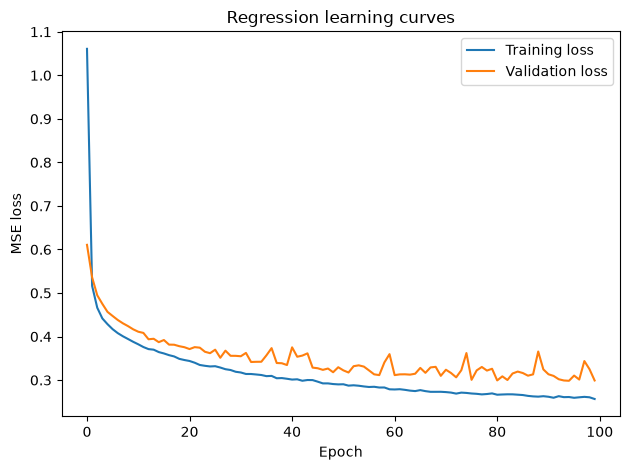

In [10]:
plt.plot(best_history["train_loss"], label="Training loss")
plt.plot(best_history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.legend()
plt.title("Regression learning curves")
plt.tight_layout()
plt.show()

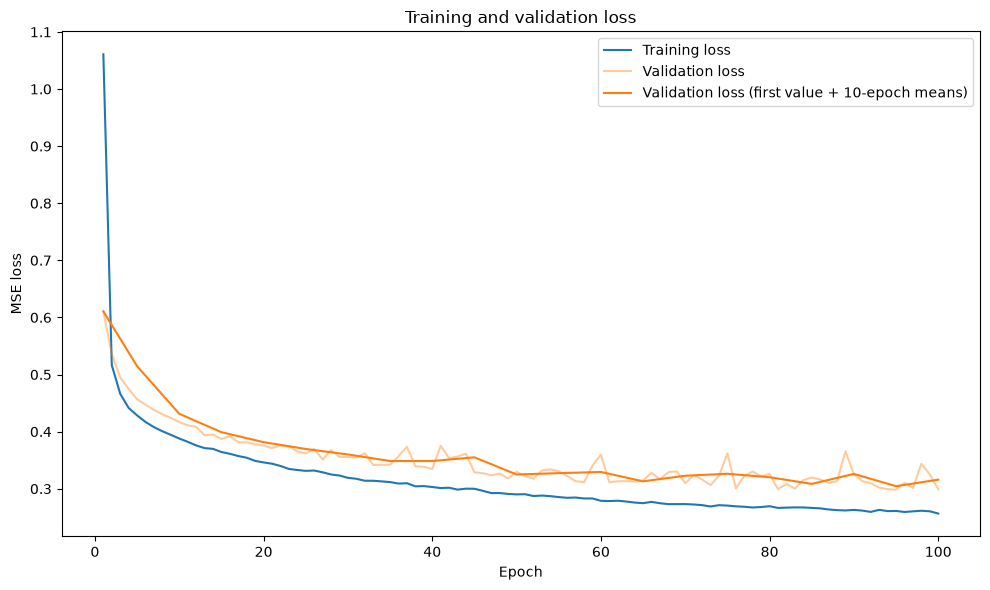

In [24]:
train_losses = np.array(best_history["train_loss"])
val_losses = np.array(best_history["val_loss"])

smooth_epochs = 5
val_losses_smoothed = np.concatenate(([val_losses[0]], val_losses.reshape(-1, smooth_epochs).mean(axis=1)))
epochs = np.arange(1, len(train_losses) + 1)
smoothed_epochs = np.concatenate(([epochs[0]], epochs[smooth_epochs - 1::smooth_epochs]))

plt.figure(figsize=(10, 6))
plt.plot(epochs, train_losses, color="tab:blue", label="Training loss")
plt.plot(epochs, val_losses, color="tab:orange", alpha=0.4, label="Validation loss")
plt.plot(smoothed_epochs, val_losses_smoothed, color="tab:orange", label="Validation loss (first value + 10-epoch means)")
plt.title("Training and validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.legend()
plt.tight_layout()
plt.show()

## 8. Final regression evaluation

Now fit preprocessing on the full training split, retrain the selected architecture, and evaluate once on the held-out test split. This gives a final performance estimate after model selection.

Training started (100 epochs).
Training | epoch 1/100 | train loss: 0.9841
Training | epoch 10/100 | train loss: 0.3845
Training | epoch 20/100 | train loss: 0.3420
Training | epoch 30/100 | train loss: 0.3158
Training | epoch 40/100 | train loss: 0.3016
Training | epoch 50/100 | train loss: 0.2904
Training | epoch 60/100 | train loss: 0.2823
Training | epoch 70/100 | train loss: 0.2796
Training | epoch 80/100 | train loss: 0.2732
Training | epoch 90/100 | train loss: 0.2668
Training | epoch 100/100 | train loss: 0.2626
Final regression model:
FeedForwardNetwork(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)
Final training loss: 0.2626
Final test MSE: 0.2833


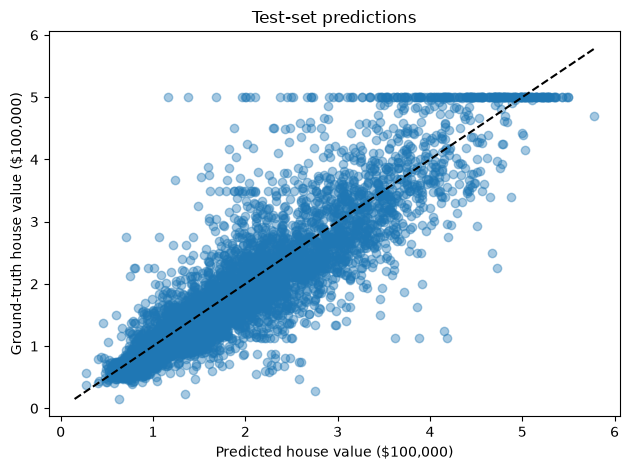

In [33]:
final_scaler = StandardScaler()
X_train_scaled = final_scaler.fit_transform(X_train)
X_test_scaled = final_scaler.transform(X_test)

final_loader = make_loader(
    X_train_scaled, y_train, best_config["batch_size"], shuffle=True
)
final_model = FeedForwardNetwork(best_config["hidden_units"]).to(DEVICE)
final_model, final_history = train_model(
    final_model,
    final_loader,
    None,
    epochs=best_config["epochs"],
    learning_rate=best_config["learning_rate"],
    loss_fn=nn.MSELoss(),
)
print("Final regression model:")
print(final_model)
print(f"Final training loss: {final_history['train_loss'][-1]:.4f}")

y_pred = predict(final_model, X_test_scaled).reshape(-1)
test_mse = mean_squared_error(y_test, y_pred)
print(f"Final test MSE: {test_mse:.4f}")

plt.scatter(y_pred, y_test, alpha=0.4)
limits = [min(float(y_pred.min()), float(y_test.min())),
          max(float(y_pred.max()), float(y_test.max()))]
plt.plot(limits, limits, "--", color="black")
plt.xlabel("Predicted house value ($100,000)")
plt.ylabel("Ground-truth house value ($100,000)")
plt.title("Test-set predictions")
plt.tight_layout()
plt.show()

**Regression interpretation:** What does the test MSE indicate? In the scatter plot, do predictions track the diagonal? Are there regions where predictions seem less accurate? Remember the target is measured in units of $100,000.

## 9. Binary classification

Convert the continuous target into two classes using the assignment cutoff of 2.0 (that is, $200,000). The network still has one output, but it represents a raw logit rather than an unrestricted value prediction. `BCEWithLogitsLoss` combines sigmoid and binary cross-entropy in a numerically stable loss, so do not put a sigmoid inside the model. Apply sigmoid only when converting logits to probabilities for evaluation.

For your report, explain these pipeline changes from regression: binary target labels, the logit output, binary cross-entropy loss, and a probability-to-class decision threshold. Explain why the confusion matrix, accuracy, precision, recall, F1, and ROC-AUC are informative for classification, including what types of errors precision and recall emphasize.

In [11]:
y_train_binary = (y_train >= 2.0).astype(np.float32)
y_test_binary = (y_test >= 2.0).astype(np.int64)

print("Training class proportions (0=below cutoff, 1=at/above cutoff):")
print(pd.Series(y_train_binary).value_counts(normalize=True).sort_index())
print("Test class proportions:")
print(pd.Series(y_test_binary).value_counts(normalize=True).sort_index())

# Fit preprocessing on the training data only.
classification_scaler = StandardScaler()
X_train_class_scaled = classification_scaler.fit_transform(X_train)
X_test_class_scaled = classification_scaler.transform(X_test)

classification_loader = make_loader(
    X_train_class_scaled,
    y_train_binary,
    best_config["batch_size"],
    shuffle=True,
)
classifier = FeedForwardNetwork(best_config["hidden_units"], output_units=1).to(DEVICE)
classification_loss = nn.BCEWithLogitsLoss()
classifier, _ = train_model(
    classifier,
    classification_loader,
    None,
    epochs=best_config["epochs"],
    learning_rate=best_config["learning_rate"],
    loss_fn=classification_loss,
)

logits = predict(classifier, X_test_class_scaled).reshape(-1)
# Clip logits before the NumPy sigmoid to avoid overflow for extreme values.
probabilities = 1.0 / (1.0 + np.exp(-np.clip(logits, -500, 500)))
y_pred_binary = (probabilities >= 0.5).astype(np.int64)

print("Confusion matrix:\n", confusion_matrix(y_test_binary, y_pred_binary))
print(f"Accuracy:  {accuracy_score(y_test_binary, y_pred_binary):.4f}")
print(f"Precision: {precision_score(y_test_binary, y_pred_binary, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test_binary, y_pred_binary, zero_division=0):.4f}")
print(f"F1:        {f1_score(y_test_binary, y_pred_binary, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test_binary, probabilities):.4f}")

Training class proportions (0=below cutoff, 1=at/above cutoff):
0.0    0.577067
1.0    0.422933
Name: proportion, dtype: float64
Test class proportions:
0    0.572093
1    0.427907
Name: proportion, dtype: float64
Training started (100 epochs).
Training | epoch 1/100 | train loss: 0.6572
Training | epoch 10/100 | train loss: 0.4194
Training | epoch 20/100 | train loss: 0.3766
Training | epoch 30/100 | train loss: 0.3597
Training | epoch 40/100 | train loss: 0.3474
Training | epoch 50/100 | train loss: 0.3367
Training | epoch 60/100 | train loss: 0.3270
Training | epoch 70/100 | train loss: 0.3182
Training | epoch 80/100 | train loss: 0.3119
Training | epoch 90/100 | train loss: 0.3064
Training | epoch 100/100 | train loss: 0.3021
Confusion matrix:
 [[2607  345]
 [ 376 1832]]
Accuracy:  0.8603
Precision: 0.8415
Recall:    0.8297
F1:        0.8356
ROC-AUC:   0.9393


**Classification interpretation:** What do the confusion matrix and each metric tell you? Is the positive class common or rare? How might that affect accuracy? The 0.5 threshold assigns the positive label when estimated probability is at least 50%; consider what kinds of errors this threshold produces.

## 10. Conclusions and report notes

Summarize your findings in your own words:

- Describe useful patterns and preprocessing choices from the feature exploration.
- State how you selected the regression architecture and learning rate using validation loss.
- Report and interpret the final regression test MSE and prediction plot.
- Report and interpret the classification metrics, including class balance and the threshold.
- Discuss limitations, possible sources of error, and what you would try next.

Before submission, restart the kernel and run all cells from top to bottom to ensure the results are reproducible and that no cell depends on hidden state.